<a href="https://colab.research.google.com/github/muktarsaputar/CAPSTONE_DB15/blob/main/capstonedb15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

memuat dataset

In [4]:
df = pd.read_csv('/content/Grocery_Inventory_and_Sales_Dataset.csv')
df.head()

,Product_ID,Product_Name,Catagory,Supplier_ID,Supplier_Name,Stock_Quantity,Reorder_Level,Reorder_Quantity,Unit_Price,Date_Received,Last_Order_Date,Expiration_Date,Warehouse_Location,Sales_Volume,Inventory_Turnover_Rate,Status
0,29-205-1132,Sushi Rice,Grains & Pulses,38-037-1699,Jaxnation,22,72,70,$4.50,8/16/2024,6/29/2024,9/19/2024,48 Del Sol Trail,32,19,Discontinued
1,40-681-9981,Arabica Coffee,Beverages,54-470-2479,Feedmix,45,77,2,$20.00,11/1/2024,5/29/2024,5/8/2024,36 3rd Place,85,1,Discontinued
2,06-955-3428,Black Rice,Grains & Pulses,54-031-2945,Vinder,30,38,83,$6.00,8/3/2024,6/10/2024,9/22/2024,3296 Walton Court,31,34,Backordered
3,71-594-6552,Long Grain Rice,Grains & Pulses,63-492-7603,Brightbean,12,59,62,$1.50,12/8/2024,2/19/2025,4/17/2024,3 Westerfield Crossing,95,99,Active
4,57-437-1828,Plum,Fruits & Vegetables,54-226-4308,Topicstorm,37,30,74,$4.00,7/3/2024,10/11/2024,10/5/2024,15068 Scoville Court,62,25,Backordered


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Product_ID               990 non-null    object
 1   Product_Name             990 non-null    object
 2   Catagory                 989 non-null    object
 3   Supplier_ID              990 non-null    object
 4   Supplier_Name            990 non-null    object
 5   Stock_Quantity           990 non-null    int64 
 6   Reorder_Level            990 non-null    int64 
 7   Reorder_Quantity         990 non-null    int64 
 8   Unit_Price               990 non-null    object
 9   Date_Received            990 non-null    object
 10  Last_Order_Date          990 non-null    object
 11  Expiration_Date          990 non-null    object
 12  Warehouse_Location       990 non-null    object
 13  Sales_Volume             990 non-null    int64 
 14  Inventory_Turnover_Rate  990 non-null    i

In [13]:
# Menghapus daftar kolom yang tidak relevan dengan prediksi jika kolom tersebut ada di df
kolom_dibuang = ['Product_ID', 'Supplier_ID', 'Supplier_Name', 'Warehouse_Location', 'Status', 'Unit_Price', 'Inventory_Turnover_Rate', 'Last_Order_Date', 'Reorder_Level']
df = df.drop(columns=kolom_dibuang, errors='ignore')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Product_Name      990 non-null    object
 1   Catagory          989 non-null    object
 2   Stock_Quantity    990 non-null    int64 
 3   Reorder_Quantity  990 non-null    int64 
 4   Date_Received     990 non-null    object
 5   Expiration_Date   990 non-null    object
 6   Sales_Volume      990 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 54.3+ KB


In [15]:
df = df.rename(columns={
    'Catagory': 'kategori',
    'Stock_Quantity': 'Jumlah_stok',
    'Reorder_Quantity': 'Jumlah_permintaan',
    'Sales_Volume': 'Jumlah_penjualan',
    'Expiration_Date': 'Tanggal_kadaluarsa',
    'Date_Recived': 'tanggal_diterima_pesanan',
    'Product_Name': 'nama_produk'

})

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 990 entries, 0 to 989
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   nama_produk         990 non-null    object
 1   kategori            989 non-null    object
 2   Jumlah_stok         990 non-null    int64 
 3   Jumlah_permintaan   990 non-null    int64 
 4   Date_Received       990 non-null    object
 5   Tanggal_kadaluarsa  990 non-null    object
 6   Jumlah_penjualan    990 non-null    int64 
dtypes: int64(3), object(4)
memory usage: 54.3+ KB


In [17]:
df.describe()

,Jumlah_stok,Jumlah_permintaan,Jumlah_penjualan
count,990.000000,990.000000,990.000000
mean,55.609091,51.913131,58.925253
std,26.300775,29.521059,23.002318
min,10.000000,1.000000,20.000000
25%,33.000000,25.000000,39.000000
50%,56.000000,54.000000,58.000000
75%,79.000000,77.000000,78.000000
max,100.000000,100.000000,100.000000


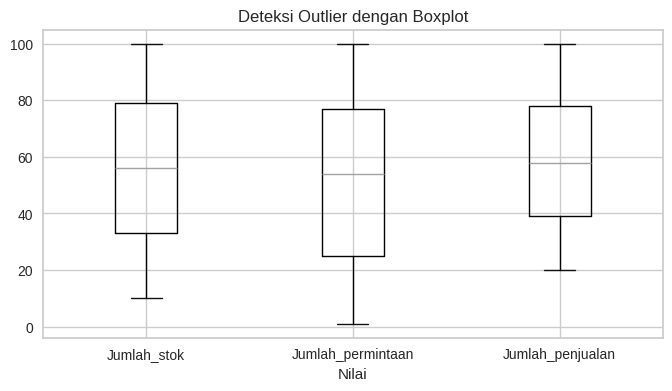

In [20]:
plt.figure(figsize=(8, 4))
df.boxplot(column=['Jumlah_stok', 'Jumlah_permintaan','Jumlah_penjualan'])
plt.title('Deteksi Outlier dengan Boxplot')
plt.xlabel('Nilai')
plt.show()

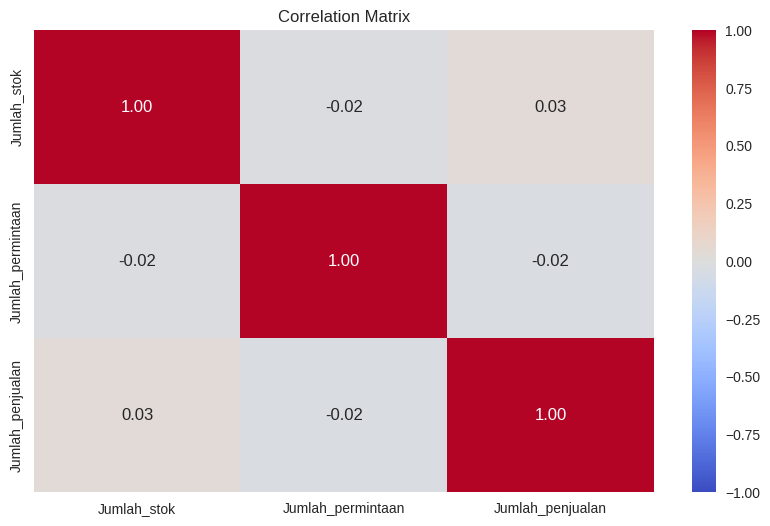

In [21]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)

# Memilih kolom numerik
numerical_cols = df.select_dtypes(include=['number']).columns

### MULAI CODE ###

# Hitung matriks korelasi
correlation = df[numerical_cols].corr()

# Buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()

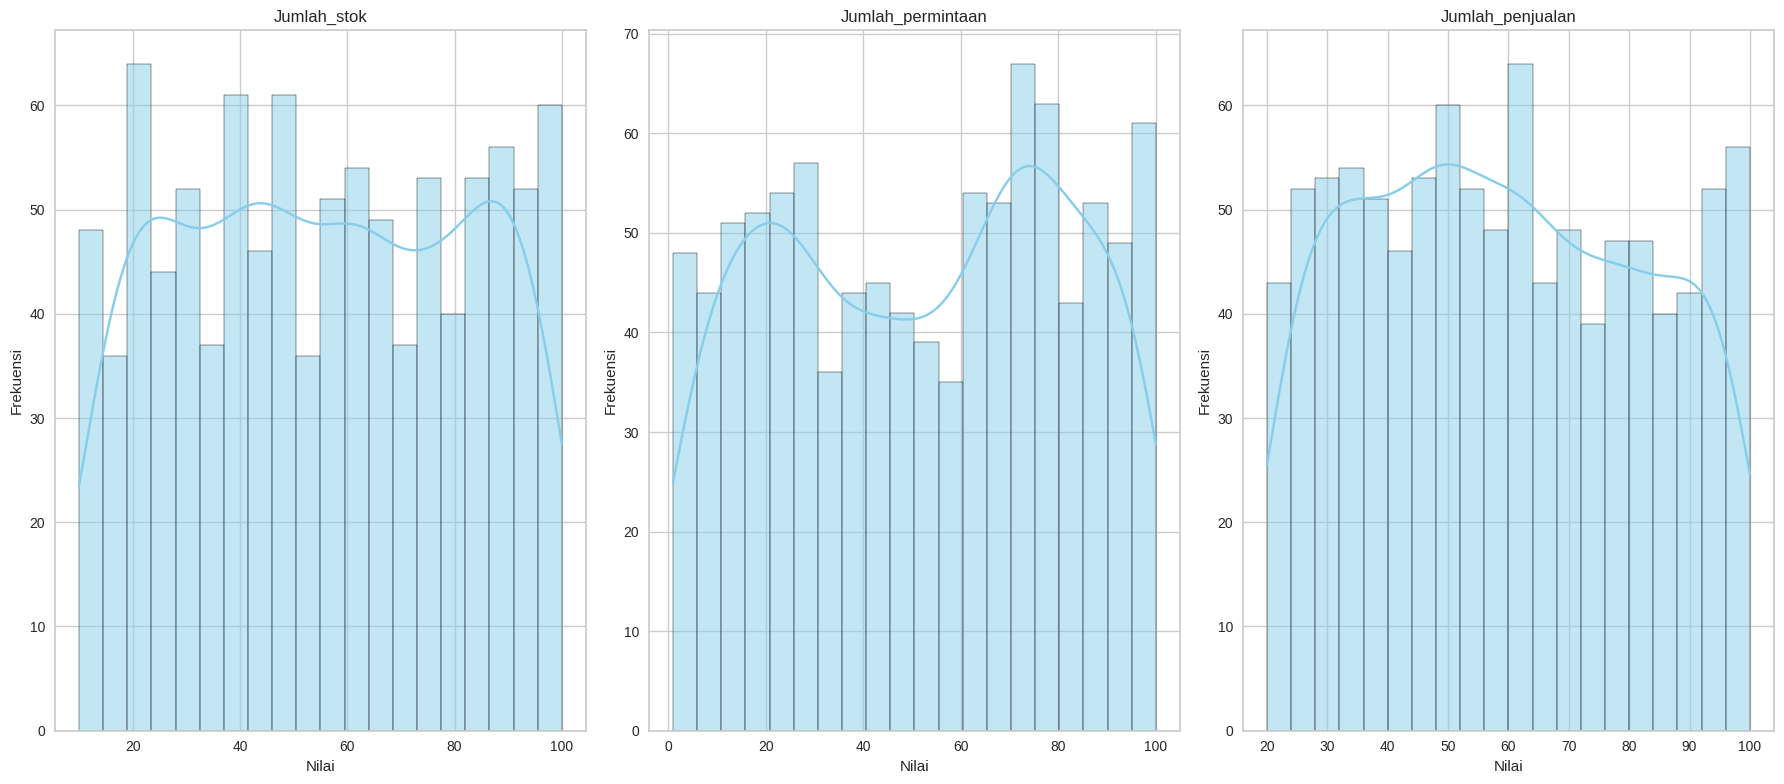

In [23]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    ### MULAI CODE ###

    # Tampilkan histogram dan pastikan plot ditempatkan di subplot (axes) yang benar
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Atur judul dan label
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

    ### SELESAI CODE ###

plt.tight_layout()
plt.show()

/tmp/ipykernel_2364/2168121640.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=cat_stock, x='Jumlah_stok', y='kategori', palette='Blues_r')


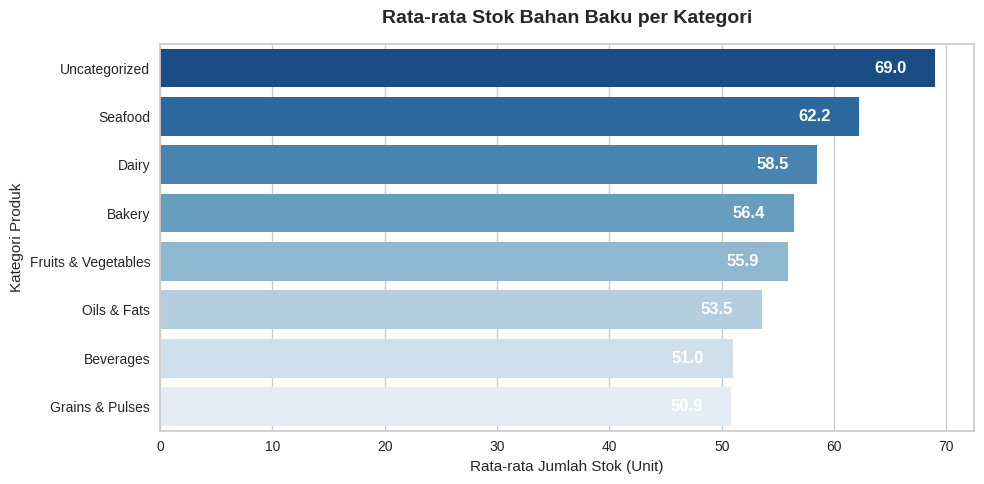

In [24]:

df['kategori'] = df['kategori'].fillna('Uncategorized')

plt.figure(figsize=(10, 5))
cat_stock = df.groupby('kategori')['Jumlah_stok'].mean().sort_values(ascending=False).reset_index()

ax = sns.barplot(data=cat_stock, x='Jumlah_stok', y='kategori', palette='Blues_r')
plt.title('Rata-rata Stok Bahan Baku per Kategori', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rata-rata Jumlah Stok (Unit)')
plt.ylabel('Kategori Produk')

# Menambahkan label angka
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}', (width - 4, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2364/2644336700.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Needs_Restock', palette=['#2ecc71', '#e74c3c'])


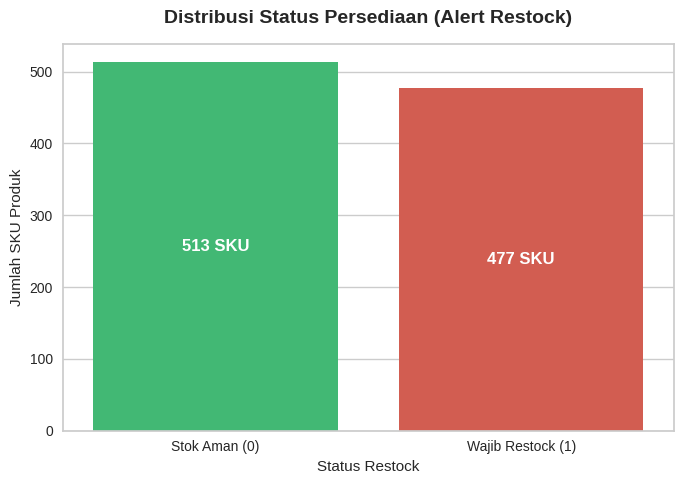

In [27]:
# Membuat variabel biner restock
df['Needs_Restock'] = (df['Jumlah_stok'] <= df['Jumlah_permintaan']).astype(int)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x='Needs_Restock', palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Status Persediaan (Alert Restock)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Status Restock')
plt.ylabel('Jumlah SKU Produk')
plt.xticks([0, 1], ['Stok Aman (0)', 'Wajib Restock (1)'])

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{int(height)} SKU', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()